# Figure 5 (K=3) — panel C relabelled from the K=3 colocalisations

The `k3` page had an inconsistency: panel C's gene labels came from the
**genome-wide K=5** colocalisation table while the heatmap itself is K=3.
This version takes them from the K=3 colocalisations instead, and sets the
gene names in italics.

Everything is drawn by `Figure5_publication`; this notebook only selects the
`k3_corrected` version and shows where the labels come from.

In [1]:
import os
import sys

import pandas as pd
from matplotlib import pyplot as plt

FIG5_DIR = '/project2/yangili1/cfbuenabadn/torino_paper/notebooks/Figure5'
ANALYSIS_DIR = '/project2/yangili1/cfbuenabadn/torino_paper/analysis'
os.chdir(ANALYSIS_DIR)
if FIG5_DIR not in sys.path:
    sys.path.append(FIG5_DIR)

import Figure5_helpers as H
import Figure5_publication as P

d = P.load_panels()
print('version:', P.VERSIONS['k3_corrected'])

version: {'twas': 'twas_panel_k3', 'knop1_k': 3, 'pooled': True, 'ir': 'ir_panel_k3_colocK3'}


## The label set

From `Fig5_numbers.ipynb` (the cell marked `### THIS TABLE`), reproduced in
`Figure5_helpers.build_k3_coloc_table()`: labelled = `ir_ad_factor`, red =
also `eQTL`. Ensembl ids are translated to symbols through the gao_k3
annotation merged with `genes.tab.gz`.

In [2]:
# Where panel C's labels come from now.
#
# Before: `iso_coloc_genes` — the 65 genes with a colocalised torino sQTL factor
# in the **genome-wide K=5** table, intersected with the heatmap, giving 9
# labels. The heatmap itself is K=3, so the two did not match.
#
# Now: the gao_k3 colocboost summary with the feature flags from
# Fig5_numbers.ipynb (the cell marked `### THIS TABLE`), reproduced in
# H.build_k3_coloc_table(). Labelled = gene_id with ir_ad_factor True; red =
# those also with eQTL True. Ensembl ids are translated through the gao_k3
# annotation merged with genes.tab.gz.
tbl = d['k3_coloc_table']
sel = tbl.loc[tbl.ir_ad_factor]
sym = H.load_k3_gene_symbols()
genes = list(dict.fromkeys(sel.gene_id))
red = set(sel.loc[sel.eQTL].gene_id)

print(f'ir_ad_factor genes : {len(genes)}   (red, i.e. eQTL too: {len(red)})')
print(pd.DataFrame({'gene': [sym.get(g, g) for g in genes],
                    'gene_id': genes,
                    'eQTL (red)': [g in red for g in genes]}).to_string(index=False))

# How many of them the heatmap can actually show: panel C is the IR-only
# progression bed, so a gene without an IR-only factor has no row to label.
in_panel = set(d['ir_panel_k3_colocK3']['order_df'].gene)
drawn = [g for g in genes if g in in_panel]
print(f'\nrows present in panel C : {len(drawn)} of {len(genes)}  '
      f'-> {[sym.get(g, g) for g in drawn]}')
print(f'absent (no IR-only factor): '
      f'{[sym.get(g, g) for g in genes if g not in in_panel]}')

ir_ad_factor genes : 18   (red, i.e. eQTL too: 13)
     gene         gene_id  eQTL (red)
   MRPL43 ENSG00000055950        True
  TSPAN14 ENSG00000108219        True
 SLC39A13 ENSG00000165915        True
    DNAL1 ENSG00000119661       False
    YPEL3 ENSG00000090238        True
    KNOP1 ENSG00000103550        True
   GPRC5B ENSG00000167191        True
C17orf100 ENSG00000256806       False
    REXO1 ENSG00000079313        True
    KLF16 ENSG00000129911       False
   ZNF638 ENSG00000075292        True
 ITGB1BP1 ENSG00000119185        True
    SIRPA ENSG00000198053        True
   RNF185 ENSG00000138942        True
   DCAF16 ENSG00000163257       False
    CPLX1 ENSG00000168993        True
   THSD7A ENSG00000005108       False
     EGFR ENSG00000146648        True

rows present in panel C : 3 of 18  -> ['TSPAN14', 'KNOP1', 'EGFR']
absent (no IR-only factor): ['MRPL43', 'SLC39A13', 'DNAL1', 'YPEL3', 'GPRC5B', 'C17orf100', 'REXO1', 'KLF16', 'ZNF638', 'ITGB1BP1', 'SIRPA', 'RNF185', 'DCAF16'

## The corrected figure

Saved as `Figure5_publication_K3_corrected.png` / `.pdf` / `.svg`.

page: 180.0 x 220.4 mm  ->  Figure5_publication_K3_corrected.png / .pdf / .svg


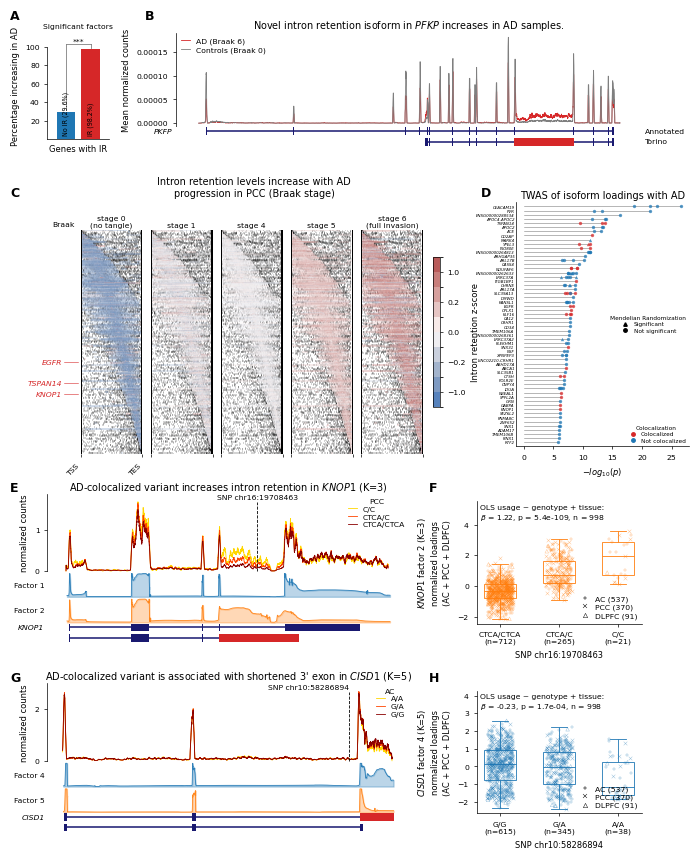

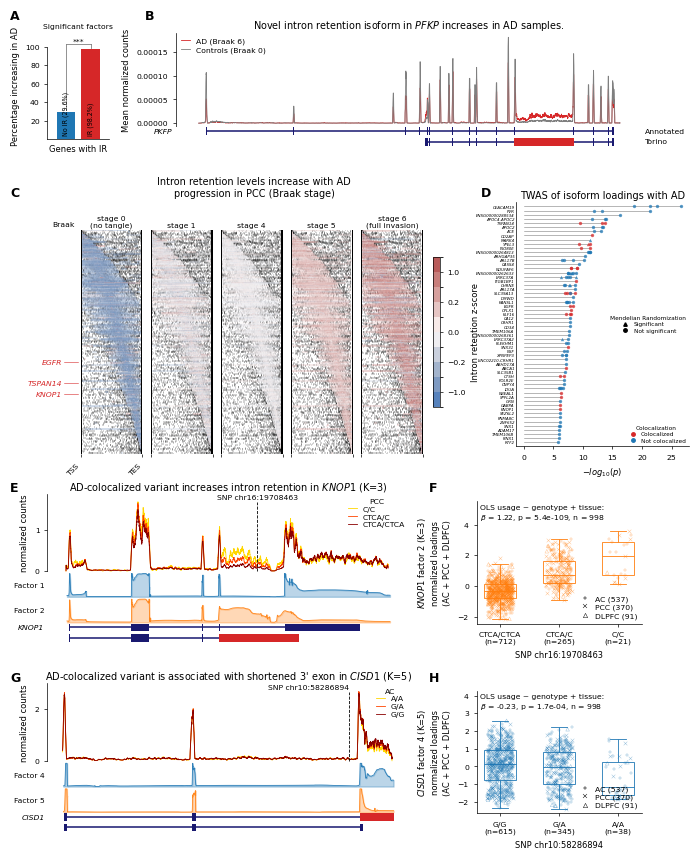

In [3]:
fig = P.save(P.build_figure(d, version='k3_corrected'),
             'Figure5_publication_K3_corrected')
print(f'page: {P.PAGE_W:.1f} x {P.PAGE_H:.1f} mm  ->  '
      f'Figure5_publication_K3_corrected.png / .pdf / .svg')
fig